# 06 – Interpretation and Marketing Profile Analysis
**IT3091 Machine Learning · Group 2026-DS-02 · Bank Marketing**

**Secondary lens: Marketing Profile Analysis.** The models predict *who* is likely to subscribe; this notebook explains *why*,
and turns the explanation into customer profiles the marketing team can act on. It also checks the model from a responsible-AI angle.

| Section | Content | Question answered |
|---|---|---|
| 1 | Setup | |
| 2 | Permutation importance (RF, XGBoost, LR) | Which inputs do the models rely on? Do they agree? |
| 3 | SHAP analysis (Random Forest, XGBoost) | In which direction does each feature push a client's score? |
| 4 | Logistic Regression odds ratios | How much does each characteristic change the odds? |
| 5 | Readable segment rules (all features; client-only) | Which simple IF–THEN segments have high / low response? |
| 6 | Who are the top-10% clients? | What does the model's priority list look like? |
| 7 | Responsible-AI check | Does the model treat age / marital groups very differently? What does removing them cost? |
| 8 | Save results | |
| 9 | Summary | |

Models are loaded as saved in `04_modelling` (no retraining, except the "age-blind" check in Section 7).
⏱ Runtime ≈ 3–6 minutes.

## 1. Setup

In [1]:
import sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import config
from src import preprocessing as prep
from src import evaluation as ev

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 200)

MODEL_ORDER = ["Logistic Regression", "Decision Tree", "Random Forest", "XGBoost"]
models = {name: joblib.load(config.MODELS_DIR / f"{name.lower().replace(' ', '_')}.joblib") for name in MODEL_ORDER}
X_train, X_test, y_train, y_test = prep.load_split()
thresholds = pd.read_csv(config.RESULTS_DIR / "thresholds_from_oof.csv", index_col=0)
rf_scores = models["Random Forest"].predict_proba(X_test)[:, 1]

# Features the models actually use (housing and loan were removed in preprocessing, D15)
USED_FEATURES = [c for c in X_test.columns if c not in prep.DROPPED_FEATURES]
CAT_USED = [c for c in prep.CAT_FEATURES if c not in prep.DROPPED_FEATURES]

def original_feature(name):
    """Map a transformed column (e.g. 'job_student', 'age_61-70') back to its original feature."""
    for c in CAT_USED + ["age"]:
        if name == c or name.startswith(c + "_"):
            return c
    return name

print(f"Test set {X_test.shape}, SHAP version {shap.__version__}")
print("Features used by the models:", USED_FEATURES)

Test set (8236, 19), SHAP version 0.52.0
Features used by the models: ['age', 'job', 'marital', 'education', 'default', 'contact', 'month', 'day_of_week', 'campaign', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'contacted_before']


## 2. Permutation importance
For each original feature, its values are **randomly shuffled** in the test set and the drop in PR-AUC is measured. A large drop means
the model relies heavily on that feature. It is computed on the full pipeline, so each **original** feature (e.g. `job`, not 12 one-hot
columns) gets one score. Repeated 5 times with different shuffles.

*Caveat:* features that carry the same information (the economic indicators) share credit. Shuffling one leaves the others intact, so each
can look less important than the group really is.

In [2]:
perm_rows = {}
for name in ["Logistic Regression", "Random Forest", "XGBoost"]:
    start = time.time()
    r = permutation_importance(models[name], X_test, y_test, scoring="average_precision",
                               n_repeats=5, random_state=config.RANDOM_STATE)
    perm_rows[name] = pd.DataFrame({"mean": r.importances_mean, "std": r.importances_std}, index=X_test.columns)
    print(f"{name:20s} done in {time.time() - start:.0f}s")

perm = pd.DataFrame({name: df["mean"] for name, df in perm_rows.items()}).drop(index=prep.DROPPED_FEATURES)
perm = perm.sort_values("Random Forest", ascending=False)
perm_std = pd.DataFrame({name: df["std"] for name, df in perm_rows.items()}).loc[perm.index]
print("Drop in test PR-AUC when the feature is shuffled (higher = more important):")
perm.round(4)

Logistic Regression  done in 5s
Random Forest        done in 27s
XGBoost              done in 7s
Drop in test PR-AUC when the feature is shuffled (higher = more important):


,Logistic Regression,Random Forest,XGBoost
nr.employed,0.0000,0.0851,0.2124
poutcome,0.0436,0.0590,0.0611
euribor3m,0.2384,0.0589,0.0188
emp.var.rate,0.0000,0.0397,0.0133
contact,0.0116,0.0346,0.0210
day_of_week,0.0041,0.0125,0.0122
campaign,0.0038,0.0117,0.0113
month,0.0251,0.0105,0.0125
cons.conf.idx,0.0060,0.0087,0.0121
cons.price.idx,0.0208,0.0071,0.0059


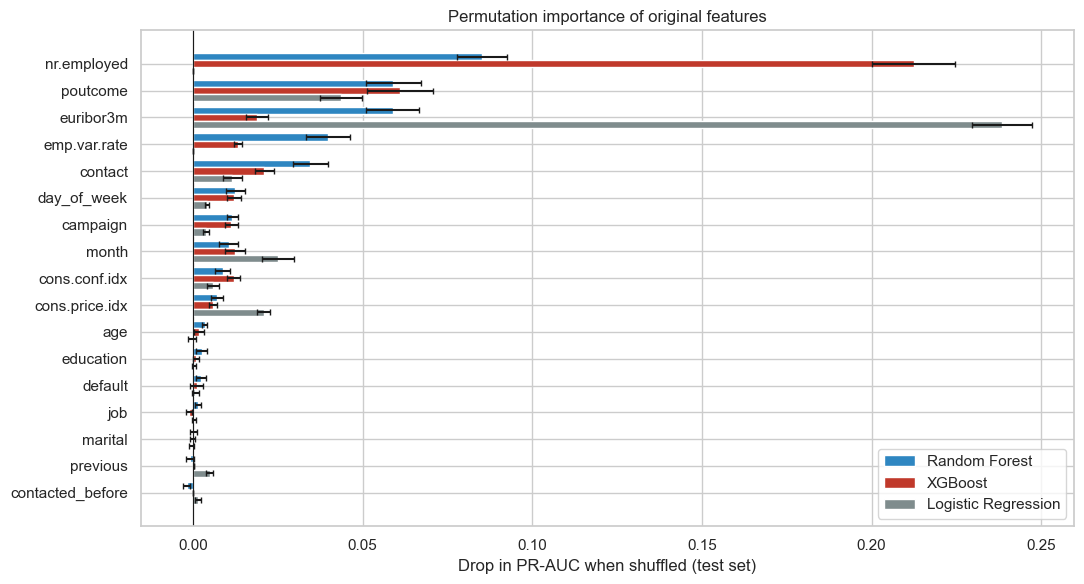

Agreement between models on feature ranking (Spearman rank correlation):


,Logistic Regression,Random Forest,XGBoost
Logistic Regression,1.00,0.33,0.43
Random Forest,0.33,1.00,0.96
XGBoost,0.43,0.96,1.00


In [3]:
fig, ax = plt.subplots(figsize=(11, 6))
ypos = np.arange(len(perm))
h = 0.27
for k, (name, color) in enumerate(zip(["Random Forest", "XGBoost", "Logistic Regression"], ["#2e86c1", "#c0392b", "#7f8c8d"])):
    ax.barh(ypos + (k - 1) * h, perm[name], height=h, xerr=perm_std[name], color=color, label=name, capsize=2)
ax.set_yticks(ypos)
ax.set_yticklabels(perm.index)
ax.invert_yaxis()
ax.axvline(0, color="k", lw=0.8)
ax.set(xlabel="Drop in PR-AUC when shuffled (test set)", title="Permutation importance of original features")
ax.legend()
plt.tight_layout()
plt.savefig(config.FIGURES / "fig17_permutation_importance.png", dpi=150, bbox_inches="tight")
plt.show()

rank_corr = perm.rank(ascending=False).corr(method="spearman")
print("Agreement between models on feature ranking (Spearman rank correlation):")
rank_corr.round(2)

## 3. SHAP analysis
SHAP splits each individual prediction into **contributions from each feature**: positive values push the client towards "yes",
negative values towards "no". Averaging the absolute values gives global importance; plotting them against feature values shows the
**direction and shape** of each effect.

Random Forest has 300 deep trees, so SHAP runs on a random sample of **1,500 test clients** (fixed seed). XGBoost uses the same sample.

In [4]:
def positive_class(values):
    """SHAP values for the 'yes' class, whatever shape the SHAP version returns."""
    if isinstance(values, list):
        return np.asarray(values[1])
    values = np.asarray(values)
    return values[..., 1] if values.ndim == 3 else values

sample = X_test.sample(n=1500, random_state=config.RANDOM_STATE)
shap_data = {}
for name in ["Random Forest", "XGBoost"]:
    pipe = models[name]
    Xt = pd.DataFrame(pipe.named_steps["prep"].transform(sample),
                      columns=pipe.named_steps["prep"].get_feature_names_out(), index=sample.index)
    start = time.time()
    explainer = shap.TreeExplainer(pipe.named_steps["model"])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        sv = positive_class(explainer.shap_values(Xt))
    shap_data[name] = (sv, Xt)
    print(f"{name:14s} SHAP values {sv.shape} in {time.time() - start:.0f}s")

Random Forest  SHAP values (1500, 54) in 145s
XGBoost        SHAP values (1500, 54) in 2s


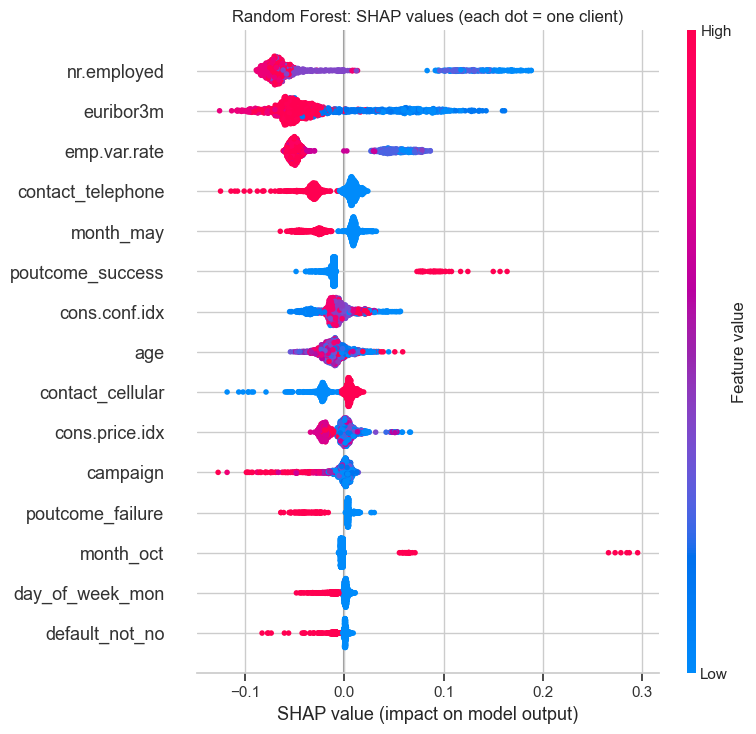

In [5]:
sv_rf, Xt_rf = shap_data["Random Forest"]
plt.figure()
shap.summary_plot(sv_rf, Xt_rf, max_display=15, show=False)
plt.title("Random Forest: SHAP values (each dot = one client)")
plt.tight_layout()
plt.savefig(config.FIGURES / "fig18_shap_summary_rf.png", dpi=150, bbox_inches="tight")
plt.show()

*How to read the beeswarm:* each row is a model input; each dot is one client. Dots to the **right** pushed that client towards "yes".
Colour shows the feature value (red = high, blue = low; for one-hot columns red = "has this category").

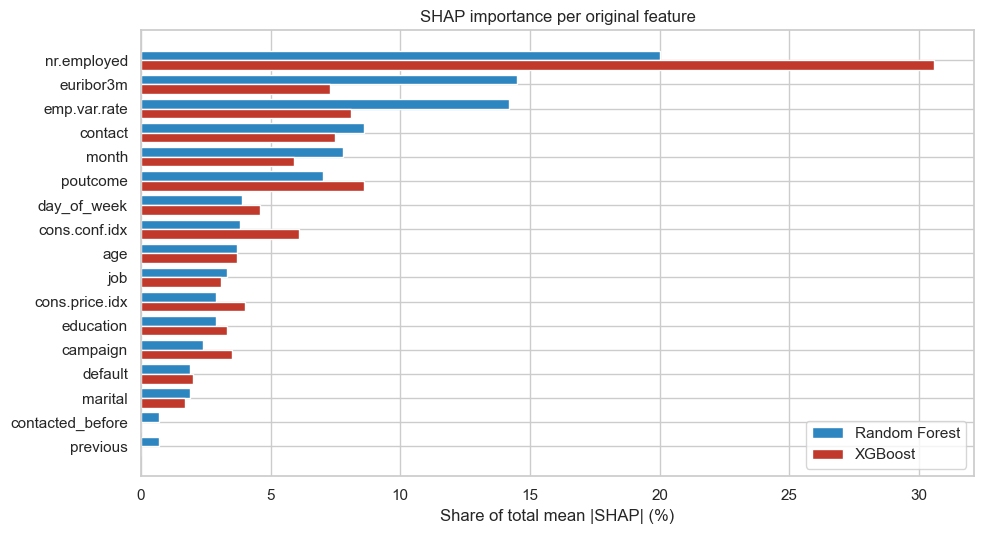

Share of total SHAP importance (%):


,Random Forest,XGBoost
nr.employed,20.0,30.6
euribor3m,14.5,7.3
emp.var.rate,14.2,8.1
contact,8.6,7.5
month,7.8,5.9
poutcome,7.0,8.6
day_of_week,3.9,4.6
cons.conf.idx,3.8,6.1
age,3.7,3.7
job,3.3,3.1


In [6]:
# Global importance per ORIGINAL feature: sum the one-hot columns' |SHAP| back together
shap_importance = {}
for name, (sv, Xt) in shap_data.items():
    per_column = pd.Series(np.abs(sv).mean(axis=0), index=Xt.columns)
    shap_importance[name] = per_column.groupby(per_column.index.map(original_feature)).sum()
shap_importance = pd.DataFrame(shap_importance).sort_values("Random Forest", ascending=False)
shap_share = (100 * shap_importance / shap_importance.sum()).round(1)

fig, ax = plt.subplots(figsize=(10, 5.5))
ypos = np.arange(len(shap_share))
ax.barh(ypos - 0.2, shap_share["Random Forest"], height=0.4, color="#2e86c1", label="Random Forest")
ax.barh(ypos + 0.2, shap_share["XGBoost"], height=0.4, color="#c0392b", label="XGBoost")
ax.set_yticks(ypos)
ax.set_yticklabels(shap_share.index)
ax.invert_yaxis()
ax.set(xlabel="Share of total mean |SHAP| (%)", title="SHAP importance per original feature")
ax.legend()
plt.tight_layout()
plt.savefig(config.FIGURES / "fig19_shap_importance_by_feature.png", dpi=150, bbox_inches="tight")
plt.show()
print("Share of total SHAP importance (%):")
shap_share

### 3.1 Direction and shape of the effects (Random Forest)
Numeric features: each dot is one client, SHAP value vs feature value. Categorical features: average SHAP value per category
(how much belonging to that category moves the score, on average).

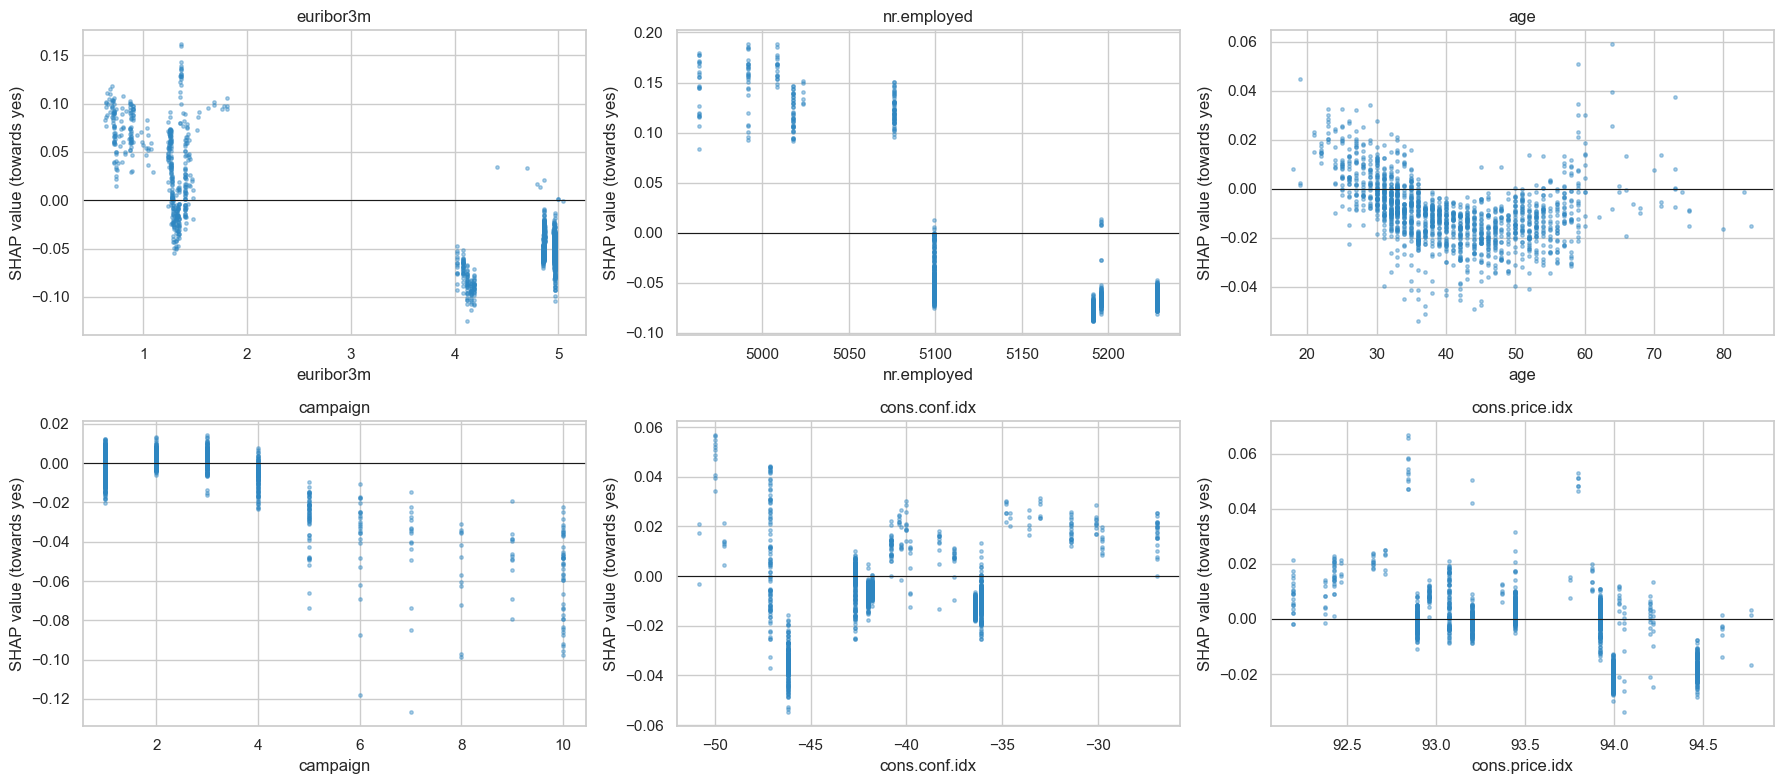

In [7]:
num_show = ["euribor3m", "nr.employed", "age", "campaign", "cons.conf.idx", "cons.price.idx"]
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, feat in zip(axes.flat, num_show):
    ax.scatter(Xt_rf[feat], sv_rf[:, list(Xt_rf.columns).index(feat)], s=6, alpha=0.4, color="#2e86c1")
    ax.axhline(0, color="k", lw=0.8)
    ax.set(xlabel=feat, ylabel="SHAP value (towards yes)", title=feat)
plt.tight_layout()
plt.savefig(config.FIGURES / "fig20_shap_dependence_numeric.png", dpi=150, bbox_inches="tight")
plt.show()

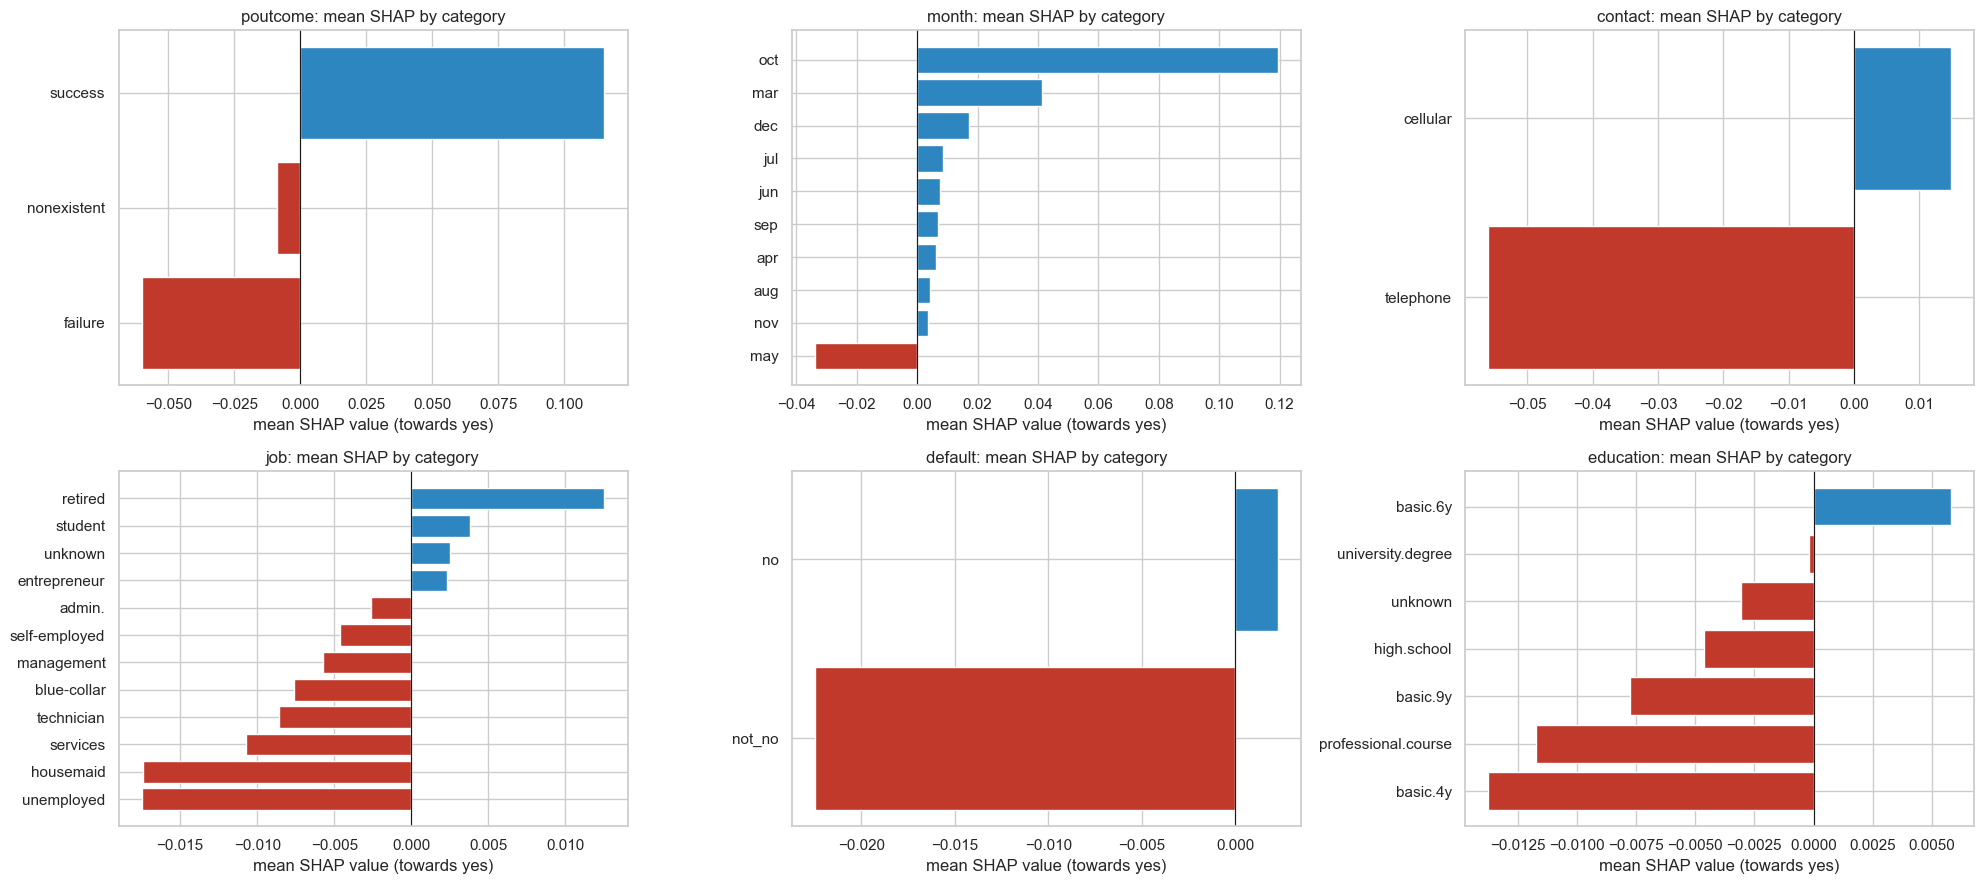


=== poutcome (mean SHAP, clients in sample) ===
               mean  size
failure     -0.0601   137
nonexistent -0.0088  1316
success      0.1153    47

=== month (mean SHAP, clients in sample) ===
       mean  size
may -0.0338   499
nov  0.0037   142
aug  0.0043   229
apr  0.0063    96
sep  0.0071    23
jun  0.0075   204
jul  0.0085   249
dec  0.0173     6
mar  0.0413    17
oct  0.1194    35

=== contact (mean SHAP, clients in sample) ===
             mean  size
telephone -0.0560   574
cellular   0.0148   926

=== job (mean SHAP, clients in sample) ===
                 mean  size
unemployed    -0.0175    45
housemaid     -0.0174    32
services      -0.0107   133
technician    -0.0086   228
blue-collar   -0.0076   349
management    -0.0057   110
self-employed -0.0046    53
admin.        -0.0026   389
entrepreneur   0.0023    49
unknown        0.0025    10
student        0.0038    33
retired        0.0125    69

=== default (mean SHAP, clients in sample) ===
          mean  size
not_no

In [8]:
cat_show = ["poutcome", "month", "contact", "job", "default", "education"]
cat_effects = {}
fig, axes = plt.subplots(2, 3, figsize=(20, 9))
for ax, feat in zip(axes.flat, cat_show):
    cols = [c for c in Xt_rf.columns if original_feature(c) == feat]
    category = Xt_rf[cols].idxmax(axis=1).str.replace(f"{feat}_", "", regex=False)   # each client's category
    contribution = pd.Series(sv_rf[:, [list(Xt_rf.columns).index(c) for c in cols]].sum(axis=1), index=Xt_rf.index)
    eff = contribution.groupby(category).agg(["mean", "size"]).sort_values("mean")
    cat_effects[feat] = eff
    ax.barh(eff.index, eff["mean"], color=np.where(eff["mean"] > 0, "#2e86c1", "#c0392b"))
    ax.axvline(0, color="k", lw=0.8)
    ax.set(title=f"{feat}: mean SHAP by category", xlabel="mean SHAP value (towards yes)")
plt.tight_layout()
plt.savefig(config.FIGURES / "fig21_shap_categorical_effects.png", dpi=150, bbox_inches="tight")
plt.show()
for feat, eff in cat_effects.items():
    print(f"\n=== {feat} (mean SHAP, clients in sample) ===")
    print(eff.round(4).to_string())

## 4. Logistic Regression odds ratios
The baseline's coefficients give the most direct interpretation. **Odds ratio = e^coefficient**: > 1 raises the odds of subscribing,
< 1 lowers them. For scaled numeric features the ratio is **per one standard deviation** increase. With one-hot encoding and regularisation,
category ratios are relative to the average client, so they are best read as **direction and relative strength**.

In [9]:
lr = models["Logistic Regression"]
lr_names = lr.named_steps["prep"].get_feature_names_out()
coef = pd.Series(lr.named_steps["model"].coef_[0], index=lr_names)
odds = pd.DataFrame({"coefficient": coef, "odds_ratio": np.exp(coef)}).sort_values("coefficient")
print("Strongest NEGATIVE effects (lower odds of subscribing):")
display(odds.head(10).round(3))
print("Strongest POSITIVE effects (higher odds of subscribing):")
display(odds.tail(10).iloc[::-1].round(3))

Strongest NEGATIVE effects (lower odds of subscribing):


,coefficient,odds_ratio
euribor3m,-0.878,0.416
poutcome_failure,-0.698,0.498
month_may,-0.692,0.501
contact_telephone,-0.206,0.814
month_aug,-0.160,0.852
age_41-50,-0.159,0.853
month_nov,-0.157,0.855
age_31-40,-0.152,0.859
default_not_no,-0.113,0.893
job_blue-collar,-0.109,0.897


Strongest POSITIVE effects (higher odds of subscribing):


,coefficient,odds_ratio
poutcome_success,0.714,2.042
month_mar,0.605,1.831
month_oct,0.347,1.415
cons.price.idx,0.232,1.261
cons.conf.idx,0.205,1.227
job_retired,0.192,1.212
contact_cellular,0.189,1.208
job_student,0.156,1.169
age_61-70,0.136,1.146
month_dec,0.119,1.127


## 5. Readable segment rules
A **shallow decision tree** (3 levels, every segment ≥ 300 clients) is fitted on the **training set** to produce simple IF–THEN segments.
It is *not* a competing model; it only translates the patterns into rules a marketing manager can read. Each segment's yes-rate is then
**checked on the test set** to confirm the profile holds on unseen clients. No class weights are used, so segment rates are real rates.

Two versions:
- **5.1 All features:** what separates high- and low-response groups overall.
- **5.2 Client and contact-history features only** (no economic indicators, no month): these describe **customer types** rather than
  time periods, so they are the actionable marketing profiles.

In [10]:
def readable(name, thr, side):
    feat = original_feature(name)
    if feat != name and feat != "age":                     # one-hot column
        category = name[len(feat) + 1:]
        return f"{feat} = {category}" if side == ">" else f"{feat} ≠ {category}"
    return f"{name} {'<=' if side == '<=' else '>'} {thr:.4g}"

def leaf_rules(tree, names):
    t = tree.tree_
    rules = {}
    def walk(node, conds):
        if t.children_left[node] == -1:
            rules[node] = conds
            return
        name, thr = names[t.feature[node]], t.threshold[node]
        walk(t.children_left[node], conds + [readable(name, thr, "<=")])
        walk(t.children_right[node], conds + [readable(name, thr, ">")])
    walk(0, [])
    return rules

def segment_table(drop):
    """Fit a 3-level rule tree on TRAIN (without the `drop` features) and check every segment on TEST."""
    pre = prep.build_preprocessor("tree", drop=prep.DROPPED_FEATURES + drop).fit(X_train)
    tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=300, criterion="entropy",
                                  random_state=config.RANDOM_STATE).fit(pre.transform(X_train), y_train)
    leaf_train, leaf_test = tree.apply(pre.transform(X_train)), tree.apply(pre.transform(X_test))
    rows = []
    for leaf, conds in leaf_rules(tree, pre.get_feature_names_out()).items():
        tr, te = leaf_train == leaf, leaf_test == leaf
        rows.append({"segment rule": "  AND  ".join(conds),
                     "train clients": int(tr.sum()), "train yes-rate %": round(100 * y_train[tr].mean(), 1),
                     "test clients": int(te.sum()), "test yes-rate %": round(100 * y_test[te].mean(), 1),
                     "lift (test)": round(y_test[te].mean() / y_test.mean(), 2)})
    out = pd.DataFrame(rows).sort_values("test yes-rate %", ascending=False).reset_index(drop=True)
    out.index = [f"S{i + 1}" for i in range(len(out))]
    return out

print(f"Overall test yes-rate: {100 * y_test.mean():.1f}%")

Overall test yes-rate: 11.3%


### 5.1 Segments using all features

In [11]:
segments_all = segment_table(drop=[])
segments_all

,segment rule,train clients,train yes-rate %,test clients,test yes-rate %,lift (test)
S1,nr.employed <= 5088 AND poutcome = success AND nr.employed <= 5013,528,77.1,120,76.7,6.80
S2,nr.employed <= 5088 AND poutcome = success AND nr.employed > 5013,374,65.2,95,64.2,5.70
S3,nr.employed <= 5088 AND poutcome ≠ success AND contact = cellular,2607,38.5,629,41.8,3.71
S4,nr.employed <= 5088 AND poutcome ≠ success AND contact ≠ cellular,478,21.8,131,26.0,2.30
S5,nr.employed > 5088 AND cons.conf.idx <= -46.65 AND poutcome ≠ failure,1667,23.7,451,23.7,2.11
S6,nr.employed > 5088 AND cons.conf.idx <= -46.65 AND poutcome = failure,502,11.0,119,9.2,0.82
S7,nr.employed > 5088 AND cons.conf.idx > -46.65 AND cons.price.idx <= 93.96,17106,6.8,4233,6.5,0.58
S8,nr.employed > 5088 AND cons.conf.idx > -46.65 AND cons.price.idx > 93.96,9678,3.5,2458,3.5,0.31


### 5.2 Customer-type segments (client + contact-history features only)

In [12]:
segments_client = segment_table(drop=list(config.ECONOMIC_FEATURES) + ["month"])
segments_client

,segment rule,train clients,train yes-rate %,test clients,test yes-rate %,lift (test)
S1,poutcome = success AND previous > 1.5,401,75.1,107,72.0,6.39
S2,poutcome = success AND previous <= 1.5 AND campaign <= 1.5,372,58.9,88,65.9,5.85
S3,poutcome = success AND previous <= 1.5 AND campaign > 1.5,321,62.9,84,44.0,3.91
S4,poutcome ≠ success AND contact ≠ telephone AND age > 60.5,525,39.6,114,41.2,3.66
S5,poutcome ≠ success AND contact ≠ telephone AND age <= 60.5,19404,11.4,4822,11.6,1.03
S6,poutcome ≠ success AND contact = telephone AND age > 57.5,471,9.3,124,8.9,0.79
S7,poutcome ≠ success AND contact = telephone AND age <= 57.5,11446,4.6,2897,4.8,0.43


## 6. Who are the top-10% clients?
The 10% of test clients with the highest Random Forest scores (the first people the bank would call) are compared with the other 90%.
This is the **marketing profile of the priority list**.

In [13]:
top = rf_scores >= np.quantile(rf_scores, 0.90)
print(f"Top 10%: {top.sum()} clients, actual yes-rate {100 * y_test[top].mean():.1f}% "
      f"vs {100 * y_test[~top].mean():.1f}% for the rest")

num_profile = pd.DataFrame({
    "top 10% (median)": X_test.loc[top, ["age", "campaign", "previous", "euribor3m", "nr.employed", "cons.conf.idx"]].median(),
    "other 90% (median)": X_test.loc[~top, ["age", "campaign", "previous", "euribor3m", "nr.employed", "cons.conf.idx"]].median(),
})
num_profile.loc["contacted_before (share %)"] = [100 * X_test.loc[top, "contacted_before"].mean(),
                                                100 * X_test.loc[~top, "contacted_before"].mean()]
display(num_profile.round(2))

rows = []
for feat in ["poutcome", "contact", "month", "job", "default", "education", "marital", "day_of_week"]:
    share_top = X_test.loc[top, feat].value_counts(normalize=True)
    share_rest = X_test.loc[~top, feat].value_counts(normalize=True)
    for cat in share_top.index:
        rows.append({"feature": feat, "category": cat,
                     "share in top 10% (%)": round(100 * share_top[cat], 1),
                     "share in other 90% (%)": round(100 * share_rest.get(cat, 0), 1),
                     "over-representation (x)": round(share_top[cat] / max(share_rest.get(cat, 0), 1e-9), 2)})
top_profile = pd.DataFrame(rows)
print("Categories most over-represented in the top 10% (at least 5% of the top group):")
top_profile[top_profile["share in top 10% (%)"] >= 5].sort_values("over-representation (x)", ascending=False).head(15)

Top 10%: 824 clients, actual yes-rate 53.2% vs 6.6% for the rest


,top 10% (median),other 90% (median)
age,36.00,38.00
campaign,1.00,2.00
previous,0.00,0.00
euribor3m,0.88,4.86
nr.employed,5017.50,5195.80
cons.conf.idx,-38.30,-41.80
contacted_before (share %),42.84,10.29


Categories most over-represented in the top 10% (at least 5% of the top group):


,feature,category,share in top 10% (%),share in other 90% (%),over-representation (x)
8,month,mar,11.8,0.2,51.33
1,poutcome,success,27.2,0.7,36.63
9,month,oct,11.8,0.5,22.37
11,month,sep,8.5,0.5,16.15
18,job,student,8.7,1.5,5.78
17,job,retired,13.1,3.0,4.38
6,month,apr,13.6,5.9,2.32
2,poutcome,failure,15.7,9.6,1.64
3,contact,cellular,92.7,59.8,1.55
37,marital,single,41.0,26.6,1.54


## 7. Responsible-AI check
`age` and `marital` describe personal characteristics. Using them in marketing is common, but the bank should know (a) whether the
model selects some groups far more or less than others, and (b) what it would cost to leave them out.

**(a) Group outcomes** at the Random Forest **Capacity 20%** threshold (chosen in `05_evaluation` from training OOF predictions):
- *selection rate*: share of the group the bank would call
- *recall*: share of the group's actual subscribers who would be called
- *precision*: share of called clients in the group who subscribe

In [14]:
t_cap = thresholds.loc["Random Forest", "Capacity 20%"]
called = rf_scores >= t_cap
age_group = pd.cut(X_test["age"], bins=prep.AGE_BINS, labels=prep.AGE_LABELS)

def group_outcomes(groups):
    rows = []
    for g in pd.Series(groups).dropna().unique():
        m = np.asarray(groups == g)
        yy, cc = y_test.to_numpy()[m], called[m]
        rows.append({"group": g, "clients": int(m.sum()), "actual yes-rate %": round(100 * yy.mean(), 1),
                     "selection rate %": round(100 * cc.mean(), 1),
                     "recall %": round(100 * (cc & (yy == 1)).sum() / max(yy.sum(), 1), 1),
                     "precision %": round(100 * (cc & (yy == 1)).sum() / max(cc.sum(), 1), 1)})
    return pd.DataFrame(rows).set_index("group")

print(f"Random Forest, Capacity-20% threshold = {t_cap:.3f}")
fair_age = group_outcomes(age_group).reindex(prep.AGE_LABELS)
fair_marital = group_outcomes(X_test["marital"]).sort_values("clients", ascending=False)
display(fair_age)
display(fair_marital)

Random Forest, Capacity-20% threshold = 0.424


,clients,actual yes-rate %,selection rate %,recall %,precision %
group,,,,,
17-25,328,18.9,46.0,90.3,37.1
26-30,1106,13.8,28.0,70.6,34.8
31-40,3312,10.9,16.7,61.7,40.1
41-50,2021,7.5,12.5,54.3,32.5
51-60,1302,9.4,17.1,61.8,34.2
61-70,92,41.3,98.9,100.0,41.8
71+,75,54.7,97.3,100.0,56.2


,clients,actual yes-rate %,selection rate %,recall %,precision %
group,,,,,
married,5006,9.8,16.8,64.7,37.8
single,2307,14.3,28.8,74.8,37.1
divorced,911,11.4,15.8,54.8,39.6
unknown,12,8.3,8.3,0.0,0.0


**(b) Cost of an "age- and marital-blind" model.** The tuned Random Forest is retrained on the training set **without `age` and `marital`**
(same hyperparameters) and compared on the test set.

In [15]:
rf_best = models["Random Forest"]
blind = Pipeline([("prep", prep.build_preprocessor("tree", drop=prep.DROPPED_FEATURES + ["age", "marital"])),
                  ("model", clone(rf_best.named_steps["model"]))])
start = time.time()
blind.fit(X_train, y_train)
blind_scores = blind.predict_proba(X_test)[:, 1]
print(f"Age/marital-blind RF trained in {time.time() - start:.0f}s")

blind_compare = pd.DataFrame({
    "Random Forest (all features)": ev.score_predictions(y_test, rf_scores),
    "Random Forest without age & marital": ev.score_predictions(y_test, blind_scores),
}).T[["pr_auc", "roc_auc", "top20_capture"]]
blind_compare.loc["difference"] = blind_compare.iloc[1] - blind_compare.iloc[0]
blind_compare.round(4)

Age/marital-blind RF trained in 7s


,pr_auc,roc_auc,top20_capture
Random Forest (all features),0.4955,0.8137,0.6713
Random Forest without age & marital,0.4959,0.8140,0.6703
difference,0.0004,0.0003,-0.0011


**(c) Does removing `age` change who gets called?** If other features act as **proxies** for age, a "blind" model can still select
age groups very differently. Selection rates by age group are compared using the same rule for both models (call the top 20% of scores).

In [ ]:
sel_rows = {}
for label, s in [("with age & marital", rf_scores), ("without age & marital", blind_scores)]:
    sel = s >= np.quantile(s, 0.80)
    sel_rows[f"selection % {label}"] = pd.Series(sel, index=X_test.index).groupby(age_group, observed=True).mean().mul(100).round(1)
proxy_check = pd.DataFrame(sel_rows).reindex(prep.AGE_LABELS)
proxy_check.insert(0, "clients", age_group.value_counts().reindex(prep.AGE_LABELS))

older = X_test["age"] > 60
print(f"Possible proxies for age among clients aged 61+: {100 * (X_test.loc[older, 'job'] == 'retired').mean():.1f}% have job = retired; "
      f"median euribor3m {X_test.loc[older, 'euribor3m'].median():.2f} vs {X_test['euribor3m'].median():.2f} overall "
      f"(they were mostly contacted in the low-rate period)")
proxy_check

## 8. Save results

In [16]:
perm.to_csv(config.RESULTS_DIR / "permutation_importance.csv")
shap_share.to_csv(config.RESULTS_DIR / "shap_importance_share.csv")
odds.to_csv(config.RESULTS_DIR / "lr_odds_ratios.csv")
segments_all.to_csv(config.RESULTS_DIR / "segments_all_features.csv")
segments_client.to_csv(config.RESULTS_DIR / "segments_client_features.csv")
top_profile.to_csv(config.RESULTS_DIR / "top10_profile.csv", index=False)
fair_age.to_csv(config.RESULTS_DIR / "fairness_age.csv")
fair_marital.to_csv(config.RESULTS_DIR / "fairness_marital.csv")
blind_compare.to_csv(config.RESULTS_DIR / "age_marital_blind_comparison.csv")
proxy_check.to_csv(config.RESULTS_DIR / "age_proxy_check.csv")
print("Saved.")

Saved.


## 9. Summary
Full details: `docs/interpretation_findings.txt` · Marketing profiles: `docs/marketing_profiles.md`.

**1. What drives the predictions: mostly the economic context, then contact history and channel.**
| Share of RF SHAP importance | % |
|---|---|
| Economic indicators (nr.employed 20.0, euribor3m 14.5, emp.var.rate 14.2, cons.conf.idx 3.8, cons.price.idx 2.9) | **55.4** |
| Month | 7.8 |
| Contact channel and timing (contact 8.6, day_of_week 3.9) | 12.5 |
| Contact history (poutcome 7.0, campaign 2.4, previous 0.7, contacted_before 0.7) | 10.8 |
| Client characteristics (age 3.7, job 3.3, education 2.9, default 1.9, marital 1.9) | 13.7 |
- Permutation importance agrees: economic indicators, `poutcome` and `contact` dominate; individual client attributes each cost < 0.004 PR-AUC when shuffled.
- RF and XGBoost agree almost perfectly on feature ranking (Spearman 0.96). LR differs (0.33–0.43) because it keeps only one economic indicator (`euribor3m`), which then carries all the economic signal (0.238).
- `previous` and `contacted_before` add almost nothing on top of `poutcome`, which already contains the contact-history information.

**2. Direction of the effects** (SHAP, LR odds ratios, consistent with the EDA)
- Low `euribor3m` (< ~1.5) and low `nr.employed` (< 5,100) push strongly towards **yes**; high values towards **no**. LR: each +1 SD of euribor3m multiplies the odds by **0.42**.
- `poutcome = success`: strongest positive category (SHAP +0.115; LR odds × **2.04**); `failure` is negative (odds × 0.50).
- **Cellular** contact positive, **telephone** negative (SHAP −0.056). **May** negative (odds × 0.50); **Mar/Oct** positive (× 1.83 / 1.42).
- **Age is U-shaped** in the RF (young and 60+ positive, 35–55 negative). **Retired** and **students** positive; `default = not_no` negative.
- **Contact fatigue:** 1–3 calls neutral, ≥ 5 calls clearly negative.

**3. Segments (3-level rule tree trained on train, checked on test)**
- *All features:* the top split is the economy (`nr.employed ≤ 5,088`). Previous success in a low-employment period gives **76.7% yes (6.8×)**; high-employment periods with normal confidence (81% of test clients) give only **3.5–6.5%**.
- *Customer types (client + history only):* previous success with > 1 earlier contact **72.0% (6.4×)**; previous success and first call in this campaign **65.9%**; **mobile contact + age > 60: 41.2% (3.7×)**; mobile ≤ 60: 11.6% (average); **landline ≤ 57: 4.8% (0.43×), the largest low-value group (2,897 clients)**. Train and test rates agree closely, except one small segment (S3: 62.9% → 44.0%, 84 test clients).

**4. The priority list (top 10% by RF):** 824 clients, **53.2% yes vs 6.6%** for the rest. Mostly contacted in low-rate periods (median euribor 0.88 vs 4.86), 43% previously contacted (vs 10%), 93% on mobile, usually on their first call. Over-represented: Mar/Oct/Sep, `poutcome = success` (36.6×), students (5.8×), retired (4.4×).

**5. Responsible AI**
- At the 20% capacity threshold the model calls **98–99% of clients aged 61+** but only **12–17% of 31–60-year-olds**; singles 28.8% vs married 16.8%. These gaps follow real differences in response (61+: 41–55% yes vs 7.5–11% for middle ages), and precision is similar across groups (32–56%), but older clients would be contacted far more often.
- Removing `age` and `marital` costs **nothing** (PR-AUC 0.4959 vs 0.4955) **but does not change who is called**: the blind model still selects ~95–99% of the 61+ group, because other features act as **proxies** (73% of 61+ clients are "retired"; they were mostly contacted in the low-rate period).
- Conclusion: dropping a sensitive column is not enough to make a model "fair". Recommended: data minimisation (drop `age`/`marital`, no loss), **monitor outcomes by group**, cap contact frequency, and apply extra care for older (potentially vulnerable) customers when selling financial products.